In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
from scipy import optimize 
import hunter2024mwmodel as h2024
import barframe
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})
agama.setUnits(length=1, mass=1, velocity=1)

In [2]:
bar1=h2024.coleman2020(**h2024.coleman_components)
bar2=h2024.portail_component(**h2024.portail_bar_1)
bar3=h2024.portail_component(**h2024.portail_bar_2)    
pbar1   = agama.Potential(type='CylSpline', density=bar1,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar2   = agama.Potential(type='CylSpline', density=bar2,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar3   = agama.Potential(type='CylSpline', density=bar3,symmetry='triaxial',mmax=8,gridSizeR=40, gridSizeZ=40, Rmin=0.001, Rmax=20, Zmin=0.001, Zmax=20,)
pbar = pbar1+pbar2+pbar3

In [3]:
# the rest of the potetial 
psagA   = agama.Potential(**h2024.supermassiveblackhole)
pnsc    = agama.Potential(**h2024.nsc)
pnsd1   = agama.Potential(**h2024.NSD1,)
pnsd2   = agama.Potential(**h2024.NSD2)
pdisk1  = agama.Potential(**h2024.DISK1)
pdisk2  = agama.Potential(**h2024.DISK2)
pgdisk1 = agama.Potential(**h2024.GDISK1)
pgdisk2 = agama.Potential(**h2024.GDISK2)
phalo   = agama.Potential(**h2024.EINASTO)
pot_total=agama.Potential(pbar1,pbar2,pbar3,psagA,pnsc,pnsd1,pnsd2,pdisk1,pdisk2,pgdisk1,pgdisk2,phalo)

In [4]:
omega=-37.5
norbits=100
ics=barframe.sample_phase_space_within_bar(pot_total,omega,norbits=norbits,seed=10,weighting='phase_space')
ics=barframe.to_inertial_velocity(ics,omega=omega)

In [7]:
traj=agama.orbit(ic=ics,potential=pot_total,Omega=omega,dtype=object,time=1,separateTime=True)

100 orbits complete (75.99 orbits/s)


In [8]:
colors=numpy.random.random((norbits,3))

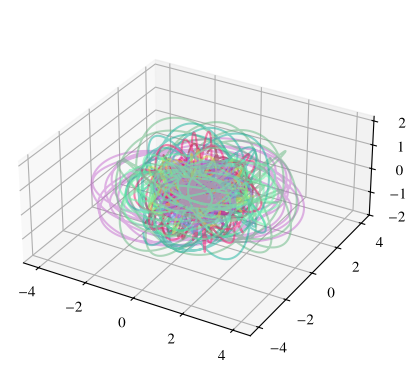

In [10]:
fig=plt.figure()
axis=fig.add_subplot(111,projection="3d")
timestamps = numpy.linspace(0,1,int(1e4))
color=matplotlib.cm
for index in range(10):
    axis.plot(traj[index].x(timestamps),traj[index].y(timestamps),traj[index].z(timestamps),alpha=.5,color=colors[index])
axis.set(aspect="equal");

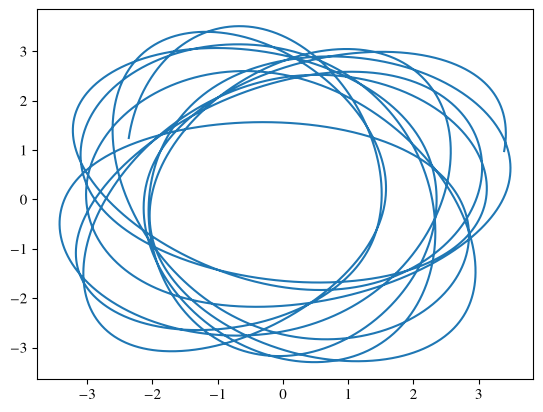

In [26]:
index=90
fig,axis=plt.subplots(1,1)
axis.plot(traj[index].x(timestamps),traj[index].y(timestamps))